# XStore Benchmarks – Big Experiments

## Libraries

In [1]:
from fabric import ThreadingGroup, Connection
from chi import server, ssh
import os
import warnings
import time
import sys
sys.path.append('../scripts')
from utilities import *
warnings.filterwarnings('ignore')

## Configurations

In [2]:
sshUser = "ubuntu"
server_ips = ["172.16.5.141"]
server_local_ips = {}
client_ips = ["172.16.5.134", "172.16.5.136", "172.16.5.138", "172.16.5.133",
              "172.16.5.135", "172.16.5.137", "172.16.5.139", "172.16.5.140"]

storageType = {"HDD": "/HDD", "NVME": "/NVME_RAID-0"}
SERVER_WORKING_DIR = storageType["NVME"]


## Initialize environment


In [3]:
# These groups are for processing in parallel 
serverConnections = [makeConnection(i, user=sshUser) for i in server_ips]
clientConnections = [makeConnection(i, user=sshUser) for i in client_ips]
allConnections = (serverConnections + clientConnections)
serverGroup = ThreadingGroup.from_connections(serverConnections)
clientGroup = ThreadingGroup.from_connections(clientConnections)
allGroup = ThreadingGroup.from_connections(allConnections)

# Get local IP for server (every experiment cell needs this)
local_ips = serverGroup.run("hostname -I | cut -d ' ' -f 1", hide=True)
for i in local_ips:
    server_local_ips[i.host] = local_ips[i].stdout.strip()

# Update & Upgrade latest packages (tolerate transient apt locks: remote apt-get survives a failed cell,
# and unattended-upgrades races the first run on fresh nodes; wait on the lock instead of aborting the cell)
apt = allGroup.run("sudo apt-get update -o DPkg::Lock::Timeout=180 && sudo apt-get upgrade -y -o DPkg::Lock::Timeout=180", hide=True, warn=True)
for rconn, r in apt.items():
    if r.exited != 0:
        print(f"[apt] {rconn.host}: exit={r.exited}: {r.stderr.strip().splitlines()[-1] if r.stderr.strip() else ''}")
    else:
        print(f"[apt] {rconn.host}: ok")
rebootGroup(allGroup)

[apt] 172.16.5.139: ok
[apt] 172.16.5.134: ok
[apt] 172.16.5.136: ok
[apt] 172.16.5.140: ok
[apt] 172.16.5.135: ok
[apt] 172.16.5.141: ok
[apt] 172.16.5.133: ok
[apt] 172.16.5.137: ok
[apt] 172.16.5.138: ok


Wait for all server to come online after reboot

In [4]:
# Buffer of reboot (no more +1 min shutdown-schedule delay)
time.sleep(240)

for ip in (server_ips + client_ips):
    waitForSSH(ip, user=sshUser, timeout=1200)

## Datasets

Preparing test datasets on client nodes

In [5]:
clientGroup.put("../scripts/initData.sh")
clientGroup.run("bash initData.sh MYSTIC@IIT", hide=True);

## Benchmark server (XStore)

Prepare benchmark server

In [6]:
serverGroup.put("../scripts/_common.sh")
serverGroup.put("../scripts/XStore/initXStoreServer.sh")
serverGroup.run(f"sudo chmod -R 777 {SERVER_WORKING_DIR}; bash initXStoreServer.sh {SERVER_WORKING_DIR}", hide=True);

## Benchmark client (XBench)
Prepare benchmark client

In [12]:
clientGroup.put("../scripts/initXBenchClient.sh")
clientGroup.run("bash initXBenchClient.sh", hide=True)
clientGroup.close()

## Experiments - Settings

In [7]:
targetThreads = [1, 2, 4, 8, 16, 32, 64]
numClients = [i * len(client_ips) for i in targetThreads]

## Experiment – UNARY INSERT (SEQ)
**Perform experiments**

In [14]:
runWorkload("INSERT_UNARY_SEQ", targetThreads, server_local_ips[server_ips[0]], 9497, "XStore", client_ips, 1000, 0, serverGroup, SERVER_WORKING_DIR, "ubuntu")

[Benchmark Config]
  Target Clients     : 1
  Total Machines     : 8
  Machines Used      : 1
  Threads per Machine: 1
  Total Clients Actual : 1
[Benchmark: 1] - Schedule workload on 1794173083
[Benchmark: 1] [Client: 172.16.5.134] - Time now: 1794173064 | Delta: 19
[Benchmark: 1] [Fetch Results] [Client: 172.16.5.134] - Downloaded 1 result files
[Benchmark: 1] [Fetch Results] [Server] - Downloaded server.log
[Benchmark: 1] [Fetch Results] [Server] - Downloaded 4 system stats files
[Benchmark Config]
  Target Clients     : 2
  Total Machines     : 8
  Machines Used      : 1
  Threads per Machine: 2
  Total Clients Actual : 2
[Benchmark: 2] - Schedule workload on 1794173187
[Benchmark: 2] [Client: 172.16.5.134] - Time now: 1794173164 | Delta: 23
[Benchmark: 2] [Fetch Results] [Client: 172.16.5.134] - Downloaded 2 result files
[Benchmark: 2] [Fetch Results] [Server] - Downloaded server.log
[Benchmark: 2] [Fetch Results] [Server] - Downloaded 4 system stats files
[Benchmark Config]
  Tar

**Visualization**

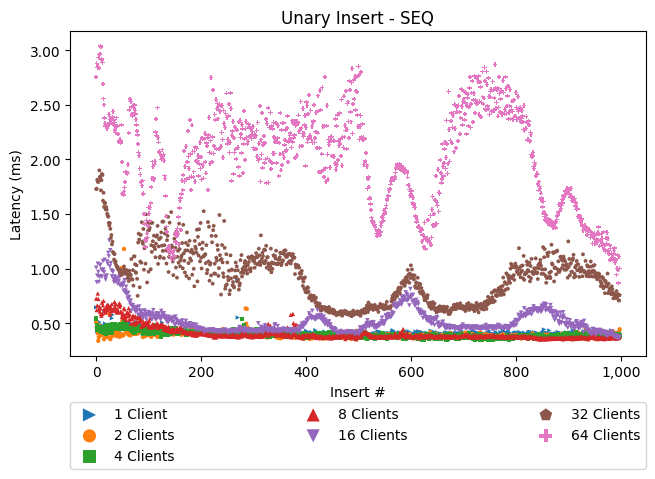

In [15]:
unaryPlots("INSERT_UNARY_SEQ", "XStore", targetThreads, client_ips, "Insert")

## Experiment – UNARY INSERT (RAND)
**Perform experiments**

In [16]:
runWorkload("INSERT_UNARY_RAND", targetThreads, server_local_ips[server_ips[0]], 9497, "XStore", client_ips, 1000, 0, serverGroup, SERVER_WORKING_DIR, "ubuntu")

[Benchmark Config]
  Target Clients     : 1
  Total Machines     : 8
  Machines Used      : 1
  Threads per Machine: 1
  Total Clients Actual : 1
[Benchmark: 1] - Schedule workload on 1794173855
[Benchmark: 1] [Client: 172.16.5.134] - Time now: 1794173832 | Delta: 23
[Benchmark: 1] [Fetch Results] [Client: 172.16.5.134] - Downloaded 1 result files
[Benchmark: 1] [Fetch Results] [Server] - Downloaded server.log
[Benchmark: 1] [Fetch Results] [Server] - Downloaded 4 system stats files
[Benchmark Config]
  Target Clients     : 2
  Total Machines     : 8
  Machines Used      : 1
  Threads per Machine: 2
  Total Clients Actual : 2
[Benchmark: 2] - Schedule workload on 1794173961
[Benchmark: 2] [Client: 172.16.5.134] - Time now: 1794173937 | Delta: 24
[Benchmark: 2] [Fetch Results] [Client: 172.16.5.134] - Downloaded 2 result files
[Benchmark: 2] [Fetch Results] [Server] - Downloaded server.log
[Benchmark: 2] [Fetch Results] [Server] - Downloaded 4 system stats files
[Benchmark Config]
  Tar

**Visualization**

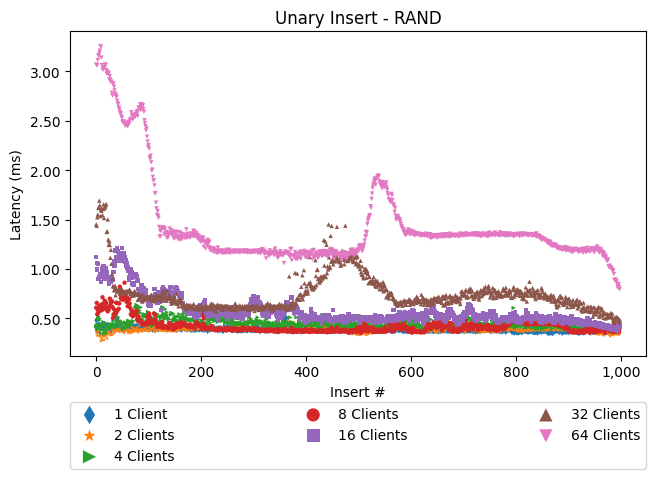

In [17]:
unaryPlots("INSERT_UNARY_RAND", "XStore", targetThreads, client_ips, "Insert")

## Experiment – BATCH INSERT (SEQ)
**Perform experiments**

In [18]:
runWorkload("INSERT_BATCH_SEQ", targetThreads, server_local_ips[server_ips[0]], 9497, "XStore", client_ips, 1000, 10, serverGroup, SERVER_WORKING_DIR, "ubuntu")

[Benchmark Config]
  Target Clients     : 1
  Total Machines     : 8
  Machines Used      : 1
  Threads per Machine: 1
  Total Clients Actual : 1
[Benchmark: 1] - Schedule workload on 1794174635
[Benchmark: 1] [Client: 172.16.5.134] - Time now: 1794174613 | Delta: 22
[Benchmark: 1] [Fetch Results] [Client: 172.16.5.134] - Downloaded 1 result files
[Benchmark: 1] [Fetch Results] [Server] - Downloaded server.log
[Benchmark: 1] [Fetch Results] [Server] - Downloaded 4 system stats files
[Benchmark Config]
  Target Clients     : 2
  Total Machines     : 8
  Machines Used      : 1
  Threads per Machine: 2
  Total Clients Actual : 2
[Benchmark: 2] - Schedule workload on 1794174741
[Benchmark: 2] [Client: 172.16.5.134] - Time now: 1794174719 | Delta: 22
[Benchmark: 2] [Fetch Results] [Client: 172.16.5.134] - Downloaded 2 result files
[Benchmark: 2] [Fetch Results] [Server] - Downloaded server.log
[Benchmark: 2] [Fetch Results] [Server] - Downloaded 4 system stats files
[Benchmark Config]
  Tar

**Visualization**

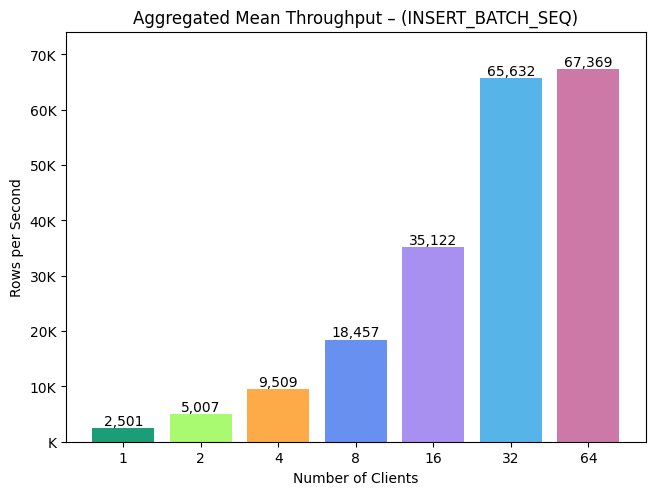

In [19]:
batchPlots("INSERT_BATCH_SEQ", "XStore", targetThreads, client_ips)

## Experiment – BATCH INSERT (RAND)
**Perform experiments**

In [20]:
runWorkload("INSERT_BATCH_RAND", targetThreads, server_local_ips[server_ips[0]], 9497, "XStore", client_ips, 1000, 10, serverGroup, SERVER_WORKING_DIR, "ubuntu")

[Benchmark Config]
  Target Clients     : 1
  Total Machines     : 8
  Machines Used      : 1
  Threads per Machine: 1
  Total Clients Actual : 1
[Benchmark: 1] - Schedule workload on 1794175412
[Benchmark: 1] [Client: 172.16.5.134] - Time now: 1794175390 | Delta: 22
[Benchmark: 1] [Fetch Results] [Client: 172.16.5.134] - Downloaded 1 result files
[Benchmark: 1] [Fetch Results] [Server] - Downloaded server.log
[Benchmark: 1] [Fetch Results] [Server] - Downloaded 4 system stats files
[Benchmark Config]
  Target Clients     : 2
  Total Machines     : 8
  Machines Used      : 1
  Threads per Machine: 2
  Total Clients Actual : 2
[Benchmark: 2] - Schedule workload on 1794175519
[Benchmark: 2] [Client: 172.16.5.134] - Time now: 1794175496 | Delta: 23
[Benchmark: 2] [Fetch Results] [Client: 172.16.5.134] - Downloaded 2 result files
[Benchmark: 2] [Fetch Results] [Server] - Downloaded server.log
[Benchmark: 2] [Fetch Results] [Server] - Downloaded 4 system stats files
[Benchmark Config]
  Tar

**Visualization**

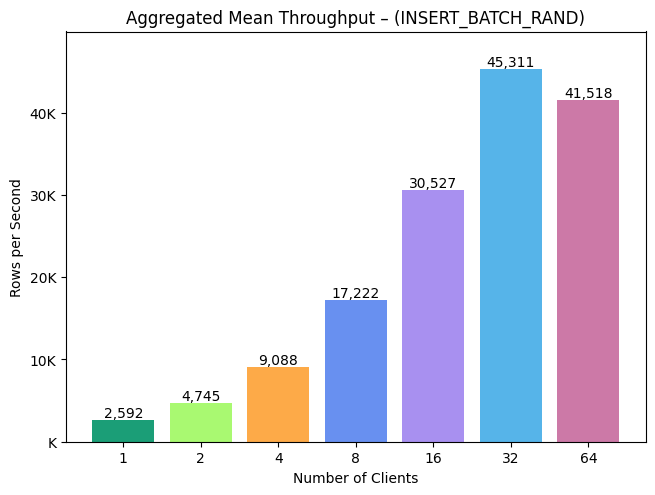

In [21]:
batchPlots("INSERT_BATCH_RAND", "XStore", targetThreads, client_ips)

## Bootstrap Database

Reboot server to a fresh state to avoid becoming non-accessible from public network


In [23]:
rebootGroup(allGroup)

# Buffer of reboot (no more +1 min shutdown-schedule delay)
time.sleep(240)

for ip in (server_ips + client_ips):
    waitForSSH(ip, user=sshUser, timeout=1200)

<div class="alert alert-block alert-info">Note: This is required so that there's actual data for clients to query from</div>

In [24]:
serverGroup.put("../scripts/restoreDB.sh")
serverGroup.put("../scripts/_common.sh")

# Before restoring: stop any running server cleanly (SIGTERM via _common.sh, docs/XStore_Handoff.md S9) so it
# is not holding DataStore.lock, then drop the stale WAL left by the insert phase -- its replay would otherwise
# run on top of the restored DB and corrupt the benchmark data.
kill = serverGroup.run("source _common.sh && killTmuxIfRunning 5", hide=True)
for resconn, res in kill.items():
    print(f"{resconn.host}: {res.stdout.strip() or 'no tmux session'}")
serverGroup.run(f"rm -rf {SERVER_WORKING_DIR}/XStore_Server/build/DataStore/WAL", hide=True)

# Restore DB
serverGroup.run(f"bash restoreDB.sh MYSTIC@IIT XStore BENCH_DB {SERVER_WORKING_DIR}", hide=True)

# Keep checking if job is done running in tmux window
checkTmuxJobIsDone(serverGroup);

172.16.5.141: no tmux session


### Post-restore start check

Start the server once, print the seconds-to-port (restored sidecars should make this fast; minutes mean stale or
old-format indexes -- see docs/BENCH_DB_Index_Refresh_Runbook.md), stop it cleanly, start again: the second number
proves the sidecar set is clean and current-format.

In [25]:
# First start after restore: seconds-to-port with the restored indexes
serverGroup.put("../scripts/_common.sh")
serverGroup.put("../scripts/XStore/runXStoreServer.sh")
first = serverGroup.run(f"bash runXStoreServer.sh false {SERVER_WORKING_DIR}", hide=True)
for resconn, res in first.items():
    print(f"{resconn.host}: {res.stdout.strip()}")

172.16.5.141: Server port 9497 open after 3s


In [26]:
# Stop cleanly (S9 helper): XStore exits on its own, indexes left clean
stopped = serverGroup.run("source _common.sh && killTmuxIfRunning 2", hide=True)
for resconn, res in stopped.items():
    print(f"{resconn.host}: {res.stdout.strip() or 'no tmux session'}")

172.16.5.141: XStore exited cleanly after 1s


In [27]:
# Second start: must be seconds, not minutes
again = serverGroup.run(f"bash runXStoreServer.sh false {SERVER_WORKING_DIR}", hide=True)
for resconn, res in again.items():
    print(f"{resconn.host}: {res.stdout.strip()}")

172.16.5.141: Server port 9497 open after 1s


## Experiment – UNARY QUERY (SEQ)

**Perform experiments**

In [28]:
runWorkload("QUERY_UNARY_SEQ", targetThreads, server_local_ips[server_ips[0]], 9497, "XStore", client_ips, 1000, 0, serverGroup, SERVER_WORKING_DIR, "ubuntu")

[Benchmark Config]
  Target Clients     : 1
  Total Machines     : 8
  Machines Used      : 1
  Threads per Machine: 1
  Total Clients Actual : 1
[Benchmark: 1] - Schedule workload on 1794181598
[Benchmark: 1] [Client: 172.16.5.134] - Time now: 1794181576 | Delta: 22
[Benchmark: 1] [Fetch Results] [Client: 172.16.5.134] - Downloaded 1 result files
[Benchmark: 1] [Fetch Results] [Server] - Downloaded server.log
[Benchmark: 1] [Fetch Results] [Server] - Downloaded 4 system stats files
[Benchmark Config]
  Target Clients     : 2
  Total Machines     : 8
  Machines Used      : 1
  Threads per Machine: 2
  Total Clients Actual : 2
[Benchmark: 2] - Schedule workload on 1794181702
[Benchmark: 2] [Client: 172.16.5.134] - Time now: 1794181679 | Delta: 23
[Benchmark: 2] [Fetch Results] [Client: 172.16.5.134] - Downloaded 2 result files
[Benchmark: 2] [Fetch Results] [Server] - Downloaded server.log
[Benchmark: 2] [Fetch Results] [Server] - Downloaded 4 system stats files
[Benchmark Config]
  Tar

**Visualization**

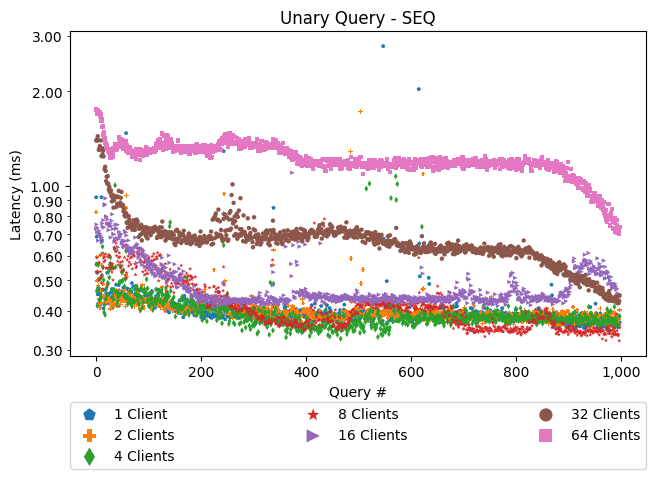

In [29]:
unaryPlots("QUERY_UNARY_SEQ", "XStore", targetThreads, client_ips, "Query", logScale=True)

## Experiment – UNARY QUERY (RAND)

**Perform experiments**

In [30]:
runWorkload("QUERY_UNARY_RAND", targetThreads, server_local_ips[server_ips[0]], 9497, "XStore", client_ips, 1000, 0, serverGroup, SERVER_WORKING_DIR, "ubuntu")

[Benchmark Config]
  Target Clients     : 1
  Total Machines     : 8
  Machines Used      : 1
  Threads per Machine: 1
  Total Clients Actual : 1
[Benchmark: 1] - Schedule workload on 1794182368
[Benchmark: 1] [Client: 172.16.5.134] - Time now: 1794182345 | Delta: 23
[Benchmark: 1] [Fetch Results] [Client: 172.16.5.134] - Downloaded 1 result files
[Benchmark: 1] [Fetch Results] [Server] - Downloaded server.log
[Benchmark: 1] [Fetch Results] [Server] - Downloaded 4 system stats files
[Benchmark Config]
  Target Clients     : 2
  Total Machines     : 8
  Machines Used      : 1
  Threads per Machine: 2
  Total Clients Actual : 2
[Benchmark: 2] - Schedule workload on 1794182472
[Benchmark: 2] [Client: 172.16.5.134] - Time now: 1794182448 | Delta: 24
[Benchmark: 2] [Fetch Results] [Client: 172.16.5.134] - Downloaded 2 result files
[Benchmark: 2] [Fetch Results] [Server] - Downloaded server.log
[Benchmark: 2] [Fetch Results] [Server] - Downloaded 4 system stats files
[Benchmark Config]
  Tar

**Visualization**

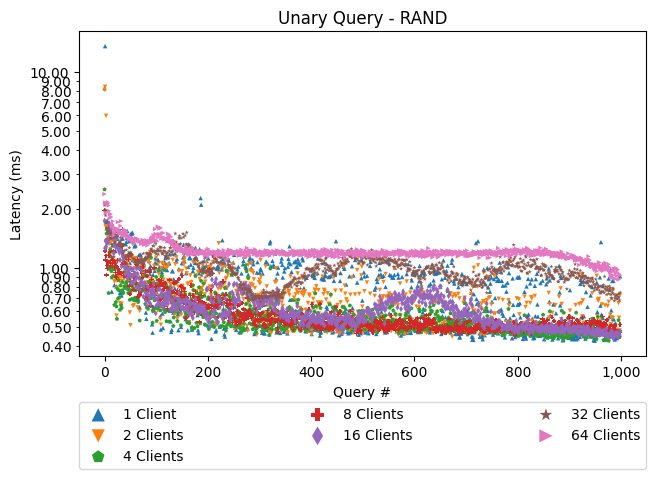

In [31]:
unaryPlots("QUERY_UNARY_RAND", "XStore", targetThreads, client_ips, "Query", logScale=True)

## Experiment – BATCH QUERY (SEQ)

**Perform experiments**

In [33]:
runWorkload("QUERY_BATCH_SEQ", targetThreads, server_local_ips[server_ips[0]], 9497, "XStore", client_ips, 100, 10, serverGroup, SERVER_WORKING_DIR, "ubuntu")

[Benchmark Config]
  Target Clients     : 1
  Total Machines     : 8
  Machines Used      : 1
  Threads per Machine: 1
  Total Clients Actual : 1
[Benchmark: 1] - Schedule workload on 1794187475
[Benchmark: 1] [Client: 172.16.5.134] - Time now: 1794187451 | Delta: 24
[Benchmark: 1] [Fetch Results] [Client: 172.16.5.134] - Downloaded 1 result files
[Benchmark: 1] [Fetch Results] [Server] - Downloaded server.log
[Benchmark: 1] [Fetch Results] [Server] - Downloaded 4 system stats files
[Benchmark Config]
  Target Clients     : 2
  Total Machines     : 8
  Machines Used      : 1
  Threads per Machine: 2
  Total Clients Actual : 2
[Benchmark: 2] - Schedule workload on 1794187578
[Benchmark: 2] [Client: 172.16.5.134] - Time now: 1794187555 | Delta: 23
[Benchmark: 2] [Fetch Results] [Client: 172.16.5.134] - Downloaded 2 result files
[Benchmark: 2] [Fetch Results] [Server] - Downloaded server.log
[Benchmark: 2] [Fetch Results] [Server] - Downloaded 4 system stats files
[Benchmark Config]
  Tar

**Visualization**

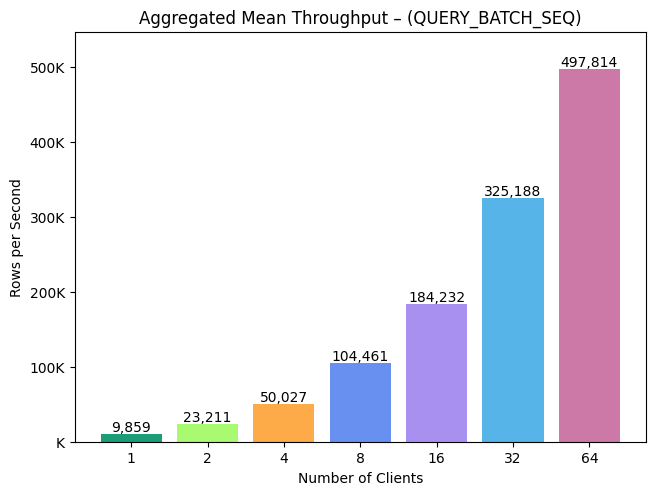

In [34]:
batchPlots("QUERY_BATCH_SEQ", "XStore", targetThreads, client_ips, 100)

## Experiment – BATCH QUERY (RAND)

**Perform experiments**

In [35]:
runWorkload("QUERY_BATCH_RAND", targetThreads, server_local_ips[server_ips[0]], 9497, "XStore", client_ips, 100, 10, serverGroup, SERVER_WORKING_DIR, "ubuntu")

[Benchmark Config]
  Target Clients     : 1
  Total Machines     : 8
  Machines Used      : 1
  Threads per Machine: 1
  Total Clients Actual : 1
[Benchmark: 1] - Schedule workload on 1794188248
[Benchmark: 1] [Client: 172.16.5.134] - Time now: 1794188224 | Delta: 24
[Benchmark: 1] [Fetch Results] [Client: 172.16.5.134] - Downloaded 1 result files
[Benchmark: 1] [Fetch Results] [Server] - Downloaded server.log
[Benchmark: 1] [Fetch Results] [Server] - Downloaded 4 system stats files
[Benchmark Config]
  Target Clients     : 2
  Total Machines     : 8
  Machines Used      : 1
  Threads per Machine: 2
  Total Clients Actual : 2
[Benchmark: 2] - Schedule workload on 1794188351
[Benchmark: 2] [Client: 172.16.5.134] - Time now: 1794188328 | Delta: 23
[Benchmark: 2] [Fetch Results] [Server] - Downloaded server.log
[Benchmark: 2] [Fetch Results] [Client: 172.16.5.134] - Downloaded 2 result files
[Benchmark: 2] [Fetch Results] [Server] - Downloaded 4 system stats files
[Benchmark Config]
  Tar

**Visualization**

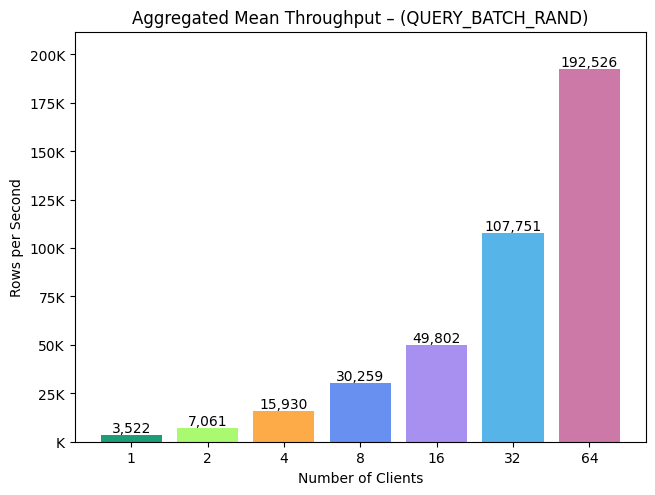

In [36]:
batchPlots("QUERY_BATCH_RAND", "XStore", targetThreads, client_ips, 100)

## Refresh Database

Reboot server to a fresh state to avoid becoming non-accessible from public network


In [37]:
rebootGroup(allGroup)

# Buffer of reboot (no more +1 min shutdown-schedule delay)
time.sleep(240)

for ip in (server_ips + client_ips):
    waitForSSH(ip, user=sshUser, timeout=1200)

## Experiment – MIN AGG QUERY

**Perform experiments**

In [38]:
runWorkload("AGG_MIN_QUERY", targetThreads, server_local_ips[server_ips[0]], 9497, "XStore", client_ips, 60, 1000, serverGroup, SERVER_WORKING_DIR, "ubuntu")

[Benchmark Config]
  Target Clients     : 1
  Total Machines     : 8
  Machines Used      : 1
  Threads per Machine: 1
  Total Clients Actual : 1
[Benchmark: 1] - Schedule workload on 1794191225
[Benchmark: 1] [Client: 172.16.5.134] - Time now: 1794191202 | Delta: 23
[Benchmark: 1] [Fetch Results] [Client: 172.16.5.134] - Downloaded 1 result files
[Benchmark: 1] [Fetch Results] [Server] - Downloaded server.log
[Benchmark: 1] [Fetch Results] [Server] - Downloaded 4 system stats files
[Benchmark Config]
  Target Clients     : 2
  Total Machines     : 8
  Machines Used      : 1
  Threads per Machine: 2
  Total Clients Actual : 2
[Benchmark: 2] - Schedule workload on 1794191329
[Benchmark: 2] [Client: 172.16.5.134] - Time now: 1794191306 | Delta: 23
[Benchmark: 2] [Fetch Results] [Client: 172.16.5.134] - Downloaded 2 result files
[Benchmark: 2] [Fetch Results] [Server] - Downloaded server.log
[Benchmark: 2] [Fetch Results] [Server] - Downloaded 4 system stats files
[Benchmark Config]
  Tar

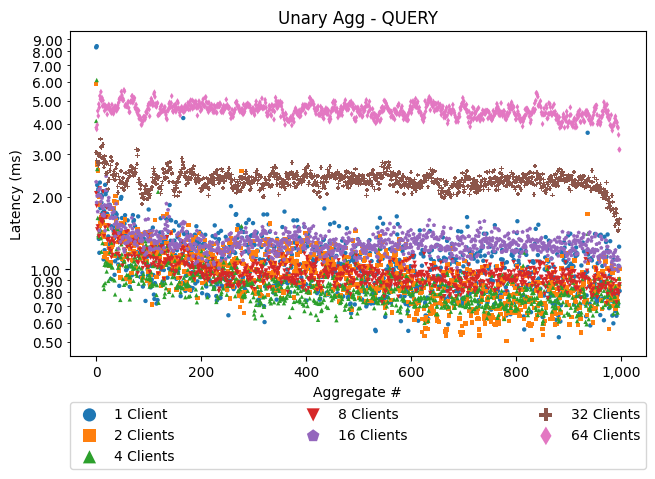

In [39]:
unaryPlots("AGG_MIN_QUERY", "XStore", targetThreads, client_ips, "Aggregate", logScale=True)

## Experiment – MAX AGG QUERY

**Perform experiments**

In [40]:
runWorkload("AGG_MAX_QUERY", targetThreads, server_local_ips[server_ips[0]], 9497, "XStore", client_ips, 60, 1000, serverGroup, SERVER_WORKING_DIR, "ubuntu")

[Benchmark Config]
  Target Clients     : 1
  Total Machines     : 8
  Machines Used      : 1
  Threads per Machine: 1
  Total Clients Actual : 1
[Benchmark: 1] - Schedule workload on 1794192002
[Benchmark: 1] [Client: 172.16.5.134] - Time now: 1794191979 | Delta: 23
[Benchmark: 1] [Fetch Results] [Client: 172.16.5.134] - Downloaded 1 result files
[Benchmark: 1] [Fetch Results] [Server] - Downloaded server.log
[Benchmark: 1] [Fetch Results] [Server] - Downloaded 4 system stats files
[Benchmark Config]
  Target Clients     : 2
  Total Machines     : 8
  Machines Used      : 1
  Threads per Machine: 2
  Total Clients Actual : 2
[Benchmark: 2] - Schedule workload on 1794192106
[Benchmark: 2] [Client: 172.16.5.134] - Time now: 1794192083 | Delta: 23
[Benchmark: 2] [Fetch Results] [Client: 172.16.5.134] - Downloaded 2 result files
[Benchmark: 2] [Fetch Results] [Server] - Downloaded server.log
[Benchmark: 2] [Fetch Results] [Server] - Downloaded 4 system stats files
[Benchmark Config]
  Tar

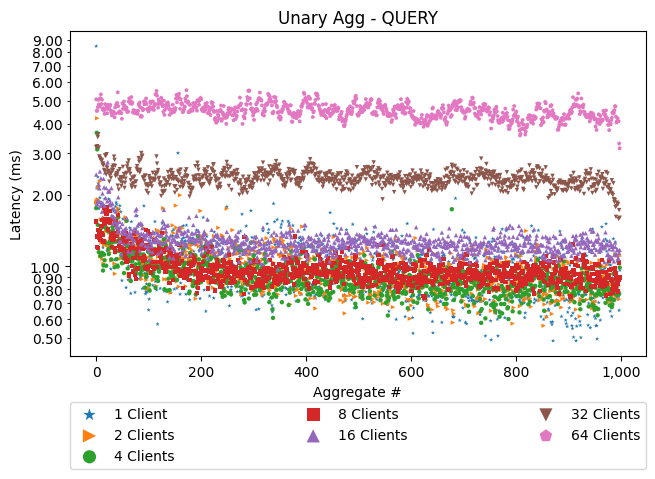

In [41]:
unaryPlots("AGG_MAX_QUERY", "XStore", targetThreads, client_ips, "Aggregate", logScale=True)

## Experiment – SUM AGG QUERY

**Perform experiments**

In [42]:
runWorkload("AGG_SUM_QUERY", targetThreads, server_local_ips[server_ips[0]], 9497, "XStore", client_ips, 60, 1000, serverGroup, SERVER_WORKING_DIR, "ubuntu")

[Benchmark Config]
  Target Clients     : 1
  Total Machines     : 8
  Machines Used      : 1
  Threads per Machine: 1
  Total Clients Actual : 1
[Benchmark: 1] - Schedule workload on 1794192784
[Benchmark: 1] [Client: 172.16.5.134] - Time now: 1794192761 | Delta: 23
[Benchmark: 1] [Fetch Results] [Client: 172.16.5.134] - Downloaded 1 result files
[Benchmark: 1] [Fetch Results] [Server] - Downloaded server.log
[Benchmark: 1] [Fetch Results] [Server] - Downloaded 4 system stats files
[Benchmark Config]
  Target Clients     : 2
  Total Machines     : 8
  Machines Used      : 1
  Threads per Machine: 2
  Total Clients Actual : 2
[Benchmark: 2] - Schedule workload on 1794192888
[Benchmark: 2] [Client: 172.16.5.134] - Time now: 1794192865 | Delta: 23
[Benchmark: 2] [Fetch Results] [Client: 172.16.5.134] - Downloaded 2 result files
[Benchmark: 2] [Fetch Results] [Server] - Downloaded server.log
[Benchmark: 2] [Fetch Results] [Server] - Downloaded 4 system stats files
[Benchmark Config]
  Tar

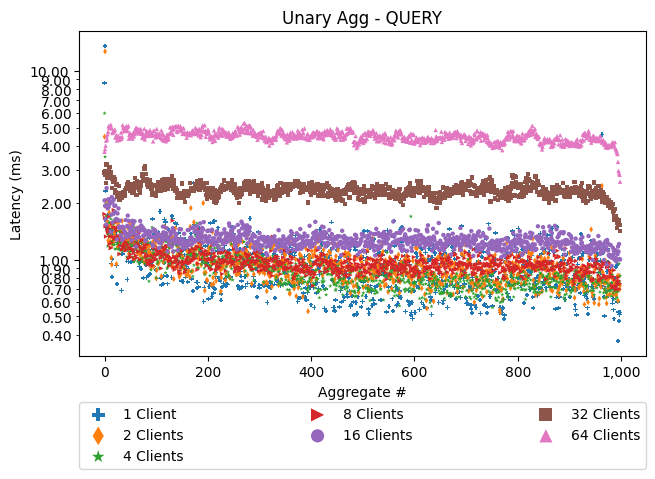

In [43]:
unaryPlots("AGG_SUM_QUERY", "XStore", targetThreads, client_ips, "Aggregate", logScale=True)

## Experiment – AVG AGG QUERY

**Perform experiments**

In [44]:
runWorkload("AGG_AVG_QUERY", targetThreads, server_local_ips[server_ips[0]], 9497, "XStore", client_ips, 60, 1000, serverGroup, SERVER_WORKING_DIR, "ubuntu")

[Benchmark Config]
  Target Clients     : 1
  Total Machines     : 8
  Machines Used      : 1
  Threads per Machine: 1
  Total Clients Actual : 1
[Benchmark: 1] - Schedule workload on 1794193567
[Benchmark: 1] [Client: 172.16.5.134] - Time now: 1794193544 | Delta: 23
[Benchmark: 1] [Fetch Results] [Server] - Downloaded server.log
[Benchmark: 1] [Fetch Results] [Client: 172.16.5.134] - Downloaded 1 result files
[Benchmark: 1] [Fetch Results] [Server] - Downloaded 4 system stats files
[Benchmark Config]
  Target Clients     : 2
  Total Machines     : 8
  Machines Used      : 1
  Threads per Machine: 2
  Total Clients Actual : 2
[Benchmark: 2] - Schedule workload on 1794193671
[Benchmark: 2] [Client: 172.16.5.134] - Time now: 1794193648 | Delta: 23
[Benchmark: 2] [Fetch Results] [Client: 172.16.5.134] - Downloaded 2 result files
[Benchmark: 2] [Fetch Results] [Server] - Downloaded server.log
[Benchmark: 2] [Fetch Results] [Server] - Downloaded 4 system stats files
[Benchmark Config]
  Tar

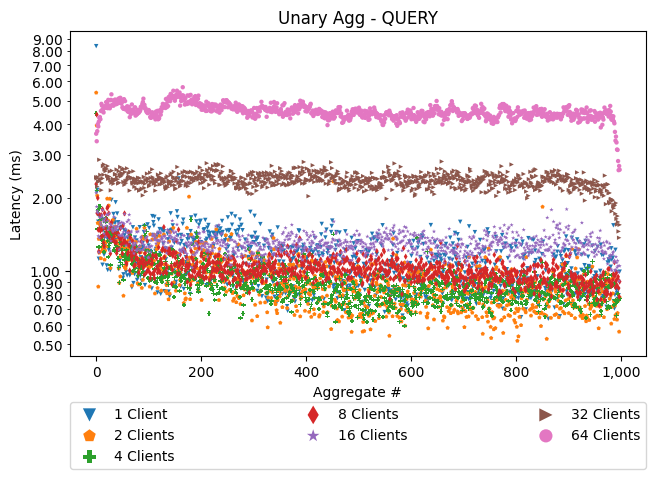

In [45]:
unaryPlots("AGG_AVG_QUERY", "XStore", targetThreads, client_ips, "Aggregate", logScale=True)

## Extended aggregates

Same sweep shape as MIN/MAX/SUM/AVG (n=60, batchSize=1000) but the workload directories are newer:
smoke-test one thread-count step first, then run the full cell, and report these separately from the core AGG set.

## Experiment – VARIANCE AGG QUERY
**Perform experiments**

In [46]:
runWorkload("AGG_VARIANCE_QUERY", targetThreads, server_local_ips[server_ips[0]], 9497, "XStore", client_ips, 60, 1000, serverGroup, SERVER_WORKING_DIR, "ubuntu")

[Benchmark Config]
  Target Clients     : 1
  Total Machines     : 8
  Machines Used      : 1
  Threads per Machine: 1
  Total Clients Actual : 1
[Benchmark: 1] - Schedule workload on 1794194358
[Benchmark: 1] [Client: 172.16.5.134] - Time now: 1794194335 | Delta: 23
[Benchmark: 1] [Fetch Results] [Client: 172.16.5.134] - Downloaded 1 result files
[Benchmark: 1] [Fetch Results] [Server] - Downloaded server.log
[Benchmark: 1] [Fetch Results] [Server] - Downloaded 4 system stats files
[Benchmark Config]
  Target Clients     : 2
  Total Machines     : 8
  Machines Used      : 1
  Threads per Machine: 2
  Total Clients Actual : 2
[Benchmark: 2] - Schedule workload on 1794194464
[Benchmark: 2] [Client: 172.16.5.134] - Time now: 1794194441 | Delta: 23
[Benchmark: 2] [Fetch Results] [Client: 172.16.5.134] - Downloaded 2 result files
[Benchmark: 2] [Fetch Results] [Server] - Downloaded server.log
[Benchmark: 2] [Fetch Results] [Server] - Downloaded 4 system stats files
[Benchmark Config]
  Tar

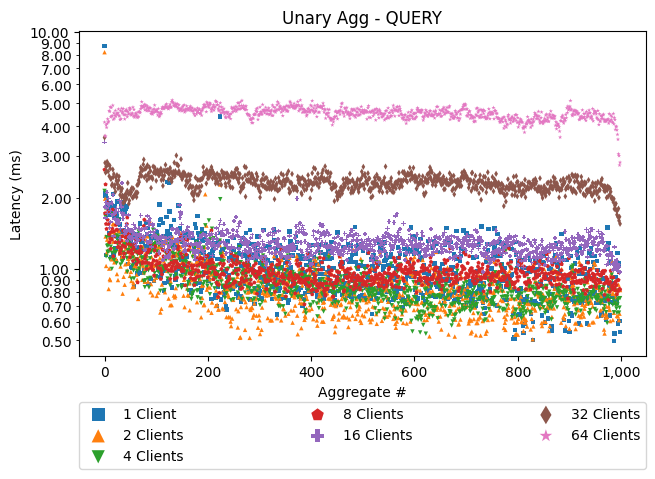

In [47]:
unaryPlots("AGG_VARIANCE_QUERY", "XStore", targetThreads, client_ips, "Aggregate", logScale=True)

## Experiment – STDDEV AGG QUERY
**Perform experiments**

In [48]:
runWorkload("AGG_STDDEV_QUERY", targetThreads, server_local_ips[server_ips[0]], 9497, "XStore", client_ips, 60, 1000, serverGroup, SERVER_WORKING_DIR, "ubuntu")

[Benchmark Config]
  Target Clients     : 1
  Total Machines     : 8
  Machines Used      : 1
  Threads per Machine: 1
  Total Clients Actual : 1
[Benchmark: 1] - Schedule workload on 1794195178
[Benchmark: 1] [Client: 172.16.5.134] - Time now: 1794195156 | Delta: 22
[Benchmark: 1] [Fetch Results] [Client: 172.16.5.134] - Downloaded 1 result files
[Benchmark: 1] [Fetch Results] [Server] - Downloaded server.log
[Benchmark: 1] [Fetch Results] [Server] - Downloaded 4 system stats files
[Benchmark Config]
  Target Clients     : 2
  Total Machines     : 8
  Machines Used      : 1
  Threads per Machine: 2
  Total Clients Actual : 2
[Benchmark: 2] - Schedule workload on 1794195284
[Benchmark: 2] [Client: 172.16.5.134] - Time now: 1794195262 | Delta: 22
[Benchmark: 2] [Fetch Results] [Client: 172.16.5.134] - Downloaded 2 result files
[Benchmark: 2] [Fetch Results] [Server] - Downloaded server.log
[Benchmark: 2] [Fetch Results] [Server] - Downloaded 4 system stats files
[Benchmark Config]
  Tar

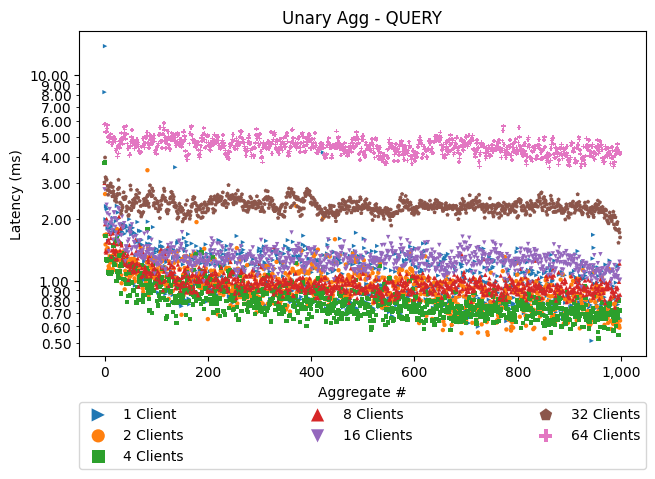

In [49]:
unaryPlots("AGG_STDDEV_QUERY", "XStore", targetThreads, client_ips, "Aggregate", logScale=True)

## Experiment – DISTINCTCOUNT AGG QUERY
**Perform experiments**

In [50]:
runWorkload("AGG_DISTINCTCOUNT_QUERY", targetThreads, server_local_ips[server_ips[0]], 9497, "XStore", client_ips, 60, 1000, serverGroup, SERVER_WORKING_DIR, "ubuntu")

[Benchmark Config]
  Target Clients     : 1
  Total Machines     : 8
  Machines Used      : 1
  Threads per Machine: 1
  Total Clients Actual : 1
[Benchmark: 1] - Schedule workload on 1794196017
[Benchmark: 1] [Client: 172.16.5.134] - Time now: 1794195995 | Delta: 22
[Benchmark: 1] [Fetch Results] [Client: 172.16.5.134] - Downloaded 1 result files
[Benchmark: 1] [Fetch Results] [Server] - Downloaded server.log
[Benchmark: 1] [Fetch Results] [Server] - Downloaded 4 system stats files
[Benchmark Config]
  Target Clients     : 2
  Total Machines     : 8
  Machines Used      : 1
  Threads per Machine: 2
  Total Clients Actual : 2
[Benchmark: 2] - Schedule workload on 1794196123
[Benchmark: 2] [Client: 172.16.5.134] - Time now: 1794196100 | Delta: 23
[Benchmark: 2] [Fetch Results] [Server] - Downloaded server.log
[Benchmark: 2] [Fetch Results] [Client: 172.16.5.134] - Downloaded 2 result files
[Benchmark: 2] [Fetch Results] [Server] - Downloaded 4 system stats files
[Benchmark Config]
  Tar

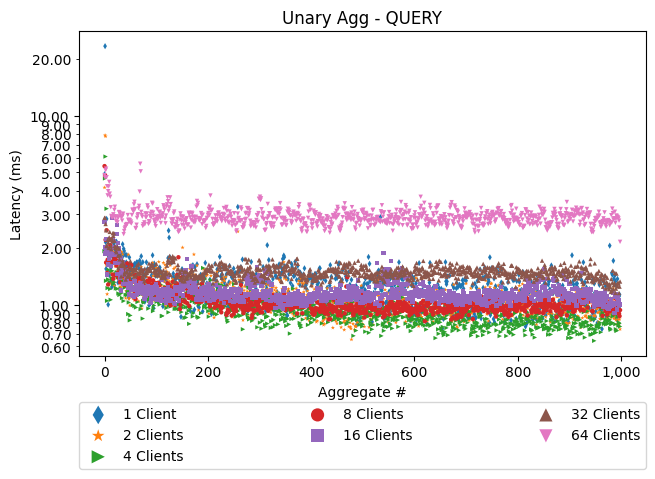

In [51]:
unaryPlots("AGG_DISTINCTCOUNT_QUERY", "XStore", targetThreads, client_ips, "Aggregate", logScale=True)

## Experiment – EXISTS AGG QUERY
**Perform experiments**

In [52]:
runWorkload("AGG_EXISTS_QUERY", targetThreads, server_local_ips[server_ips[0]], 9497, "XStore", client_ips, 60, 1000, serverGroup, SERVER_WORKING_DIR, "ubuntu")

[Benchmark Config]
  Target Clients     : 1
  Total Machines     : 8
  Machines Used      : 1
  Threads per Machine: 1
  Total Clients Actual : 1
[Benchmark: 1] - Schedule workload on 1794196865
[Benchmark: 1] [Client: 172.16.5.134] - Time now: 1794196842 | Delta: 23
[Benchmark: 1] [Fetch Results] [Server] - Downloaded server.log
[Benchmark: 1] [Fetch Results] [Client: 172.16.5.134] - Downloaded 1 result files
[Benchmark: 1] [Fetch Results] [Server] - Downloaded 4 system stats files
[Benchmark Config]
  Target Clients     : 2
  Total Machines     : 8
  Machines Used      : 1
  Threads per Machine: 2
  Total Clients Actual : 2
[Benchmark: 2] - Schedule workload on 1794196972
[Benchmark: 2] [Client: 172.16.5.134] - Time now: 1794196950 | Delta: 22
[Benchmark: 2] [Fetch Results] [Client: 172.16.5.134] - Downloaded 2 result files
[Benchmark: 2] [Fetch Results] [Server] - Downloaded server.log
[Benchmark: 2] [Fetch Results] [Server] - Downloaded 4 system stats files
[Benchmark Config]
  Tar

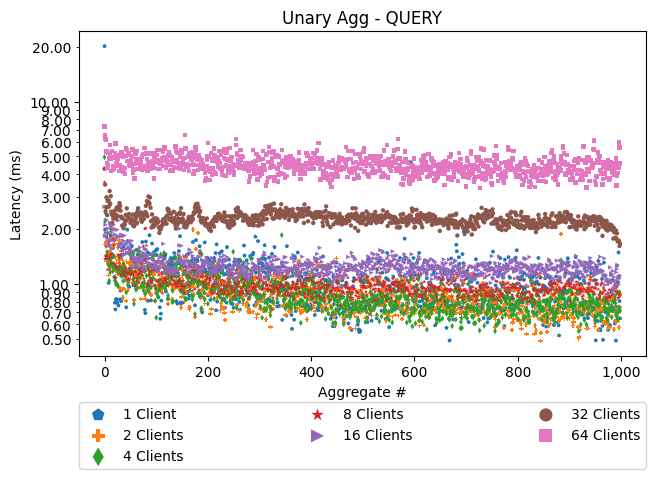

In [53]:
unaryPlots("AGG_EXISTS_QUERY", "XStore", targetThreads, client_ips, "Aggregate", logScale=True)

## Experiment – OHLC AGG QUERY
**Perform experiments**

In [54]:
runWorkload("AGG_OHLC_QUERY", targetThreads, server_local_ips[server_ips[0]], 9497, "XStore", client_ips, 60, 1000, serverGroup, SERVER_WORKING_DIR, "ubuntu")

[Benchmark Config]
  Target Clients     : 1
  Total Machines     : 8
  Machines Used      : 1
  Threads per Machine: 1
  Total Clients Actual : 1
[Benchmark: 1] - Schedule workload on 1794197731
[Benchmark: 1] [Client: 172.16.5.134] - Time now: 1794197709 | Delta: 22
[Benchmark: 1] [Fetch Results] [Server] - Downloaded server.log
[Benchmark: 1] [Fetch Results] [Client: 172.16.5.134] - Downloaded 1 result files
[Benchmark: 1] [Fetch Results] [Server] - Downloaded 4 system stats files
[Benchmark Config]
  Target Clients     : 2
  Total Machines     : 8
  Machines Used      : 1
  Threads per Machine: 2
  Total Clients Actual : 2
[Benchmark: 2] - Schedule workload on 1794197839
[Benchmark: 2] [Client: 172.16.5.134] - Time now: 1794197817 | Delta: 22
[Benchmark: 2] [Fetch Results] [Server] - Downloaded server.log
[Benchmark: 2] [Fetch Results] [Client: 172.16.5.134] - Downloaded 2 result files
[Benchmark: 2] [Fetch Results] [Server] - Downloaded 4 system stats files
[Benchmark Config]
  Tar

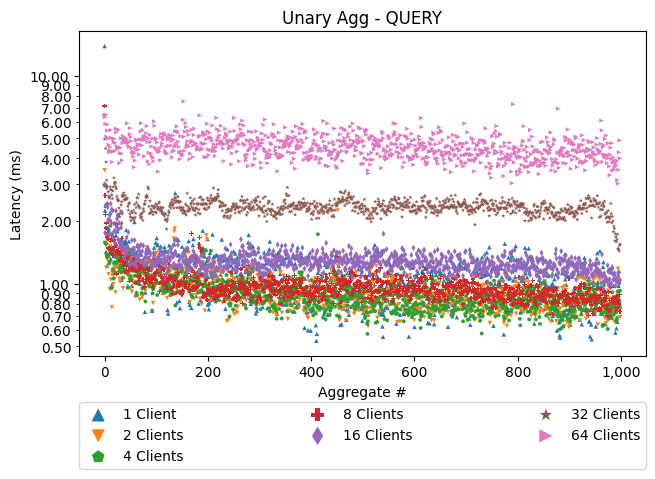

In [55]:
unaryPlots("AGG_OHLC_QUERY", "XStore", targetThreads, client_ips, "Aggregate", logScale=True)

## Experiment – PERCENTILE AGG QUERY
**Perform experiments**

In [56]:
runWorkload("AGG_PERCENTILE_QUERY", targetThreads, server_local_ips[server_ips[0]], 9497, "XStore", client_ips, 60, 1000, serverGroup, SERVER_WORKING_DIR, "ubuntu")

[Benchmark Config]
  Target Clients     : 1
  Total Machines     : 8
  Machines Used      : 1
  Threads per Machine: 1
  Total Clients Actual : 1
[Benchmark: 1] - Schedule workload on 1794198622
[Benchmark: 1] [Client: 172.16.5.134] - Time now: 1794198602 | Delta: 20
[Benchmark: 1] [Fetch Results] [Server] - Downloaded server.log
[Benchmark: 1] [Fetch Results] [Client: 172.16.5.134] - Downloaded 1 result files
[Benchmark: 1] [Fetch Results] [Server] - Downloaded 4 system stats files
[Benchmark Config]
  Target Clients     : 2
  Total Machines     : 8
  Machines Used      : 1
  Threads per Machine: 2
  Total Clients Actual : 2
[Benchmark: 2] - Schedule workload on 1794198730
[Benchmark: 2] [Client: 172.16.5.134] - Time now: 1794198708 | Delta: 22
[Benchmark: 2] [Fetch Results] [Server] - Downloaded server.log
[Benchmark: 2] [Fetch Results] [Client: 172.16.5.134] - Downloaded 2 result files
[Benchmark: 2] [Fetch Results] [Server] - Downloaded 4 system stats files
[Benchmark Config]
  Tar

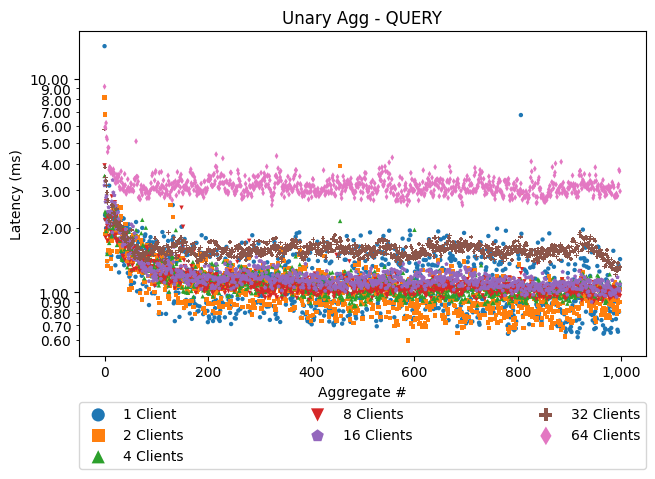

In [57]:
unaryPlots("AGG_PERCENTILE_QUERY", "XStore", targetThreads, client_ips, "Aggregate", logScale=True)

## Experiment – TOPK AGG QUERY
**Perform experiments**

In [8]:
runWorkload("AGG_TOPK_QUERY", targetThreads, server_local_ips[server_ips[0]], 9497, "XStore", client_ips, 60, 1000, serverGroup, SERVER_WORKING_DIR, "ubuntu")

[Benchmark Config]
  Target Clients     : 1
  Total Machines     : 8
  Machines Used      : 1
  Threads per Machine: 1
  Total Clients Actual : 1
[Benchmark: 1] - Schedule workload on 1794345303
[Benchmark: 1] [Client: 172.16.5.134] - Time now: 1794345280 | Delta: 23
[Benchmark: 1] [Fetch Results] [Client: 172.16.5.134] - Downloaded 1 result files
[Benchmark: 1] [Fetch Results] [Server] - Downloaded server.log
[Benchmark: 1] [Fetch Results] [Server] - Downloaded 4 system stats files
[Benchmark Config]
  Target Clients     : 2
  Total Machines     : 8
  Machines Used      : 1
  Threads per Machine: 2
  Total Clients Actual : 2
[Benchmark: 2] - Schedule workload on 1794345405
[Benchmark: 2] [Client: 172.16.5.134] - Time now: 1794345381 | Delta: 24
[Benchmark: 2] [Fetch Results] [Client: 172.16.5.134] - Downloaded 2 result files
[Benchmark: 2] [Fetch Results] [Server] - Downloaded server.log
[Benchmark: 2] [Fetch Results] [Server] - Downloaded 4 system stats files
[Benchmark Config]
  Tar

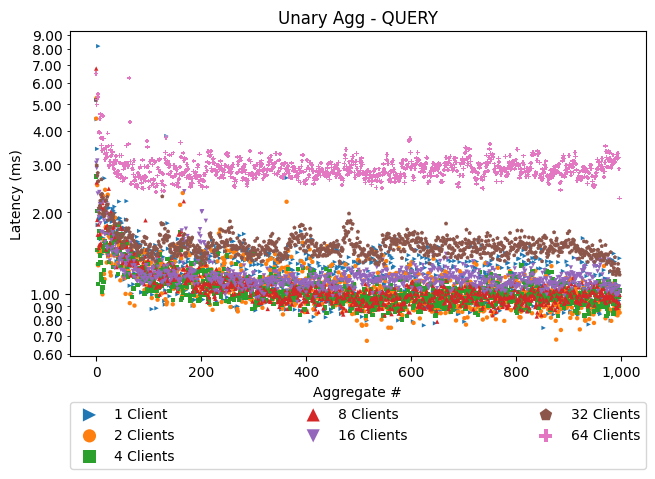

In [9]:
unaryPlots("AGG_TOPK_QUERY", "XStore", targetThreads, client_ips, "Aggregate", logScale=True)

In [63]:
import importlib, utilities
importlib.reload(utilities)
from utilities import *